# 05 — Case 2: Diameter Regression
**Inputs:** `data/processed/case2_diameter.parquet`, `reports/results/03_manifest.json`  
**Outputs:** `reports/results/05_case2_results.csv`, `models/case2_diameter_best.joblib`, figures.

## 1. Setup

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pda_utils as U

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)

QUICK = False
TRAIN_CAP = 15_000 if QUICK else None      # cap on fit rows (None = all)
RF_TREES  = 40 if QUICK else 80
XGB_TREES = 80 if QUICK else 500
LOG_MLFLOW = True

def savefig(name):
    plt.tight_layout(); plt.savefig(U.FIG / f"{name}.png", dpi=150); plt.show()

## 2. Data & splits

In [2]:
M = U.load_manifest(); FS = M["feature_sets"]
df = U.read_processed("case2")
n0 = len(df); df = df[df["albedo"].notna()].reset_index(drop=True)
print(f"rows: {n0:,} -> {len(df):,} after requiring albedo (same rows for A and B)")

SCENARIOS = {"A_noAlbedo": FS["case2_A_noAlbedo"], "B_withAlbedo": FS["case2_B_withAlbedo"]}
for k, v in SCENARIOS.items(): print(f"{k:14s} {v}")

train_all = df[df["split"] == "train"]; test = df[df["split"] == "test"].reset_index(drop=True)
fit, val = train_test_split(train_all, test_size=0.2, random_state=U.SEED)
if TRAIN_CAP: fit = fit.sample(min(TRAIN_CAP, len(fit)), random_state=U.SEED)
fit, val = fit.reset_index(drop=True), val.reset_index(drop=True)
print(f"fit={len(fit):,}  val={len(val):,}  test={len(test):,}")
df[["diameter", "log_diameter"]].describe().round(3)

rows: 132,045 -> 131,237 after requiring albedo (same rows for A and B)
A_noAlbedo     ['H_tr', 'a_tr', 'q_tr', 'ad_tr', 'i_tr', 'e_tr', 'ma_sin', 'om_sin', 'ma_cos']
B_withAlbedo   ['H_tr', 'albedo_tr', 'a_tr', 'q_tr', 'ad_tr', 'i_tr', 'e_tr', 'ma_cos', 'ma_sin']
fit=83,988  val=20,997  test=26,252


,diameter,log_diameter
count,131237.000,131237.000
mean,5.617,0.628
std,9.581,0.278
min,0.008,-2.097
25%,2.853,0.455
50%,4.059,0.608
75%,5.863,0.768
max,939.400,2.973


## 3. Metrics & baselines

In [3]:
def reg_metrics(y_log_true, y_log_pred):
    """log-space: R2/RMSE/MAE.  km-space: MAE, median relative error, share within 20%."""
    d_true, d_pred = 10 ** np.asarray(y_log_true), 10 ** np.asarray(y_log_pred)
    rel = np.abs(d_pred - d_true) / d_true
    return dict(R2_log=r2_score(y_log_true, y_log_pred),
                RMSE_log=mean_squared_error(y_log_true, y_log_pred) ** 0.5,
                MAE_log=mean_absolute_error(y_log_true, y_log_pred),
                MAE_km=mean_absolute_error(d_true, d_pred),
                median_rel_err_pct=float(np.median(rel) * 100),
                within_20pct=float((rel <= 0.20).mean() * 100))

# --- baselines on the test split ---
base = {}
base["mean (no model)"] = reg_metrics(test["log_diameter"], np.full(len(test), fit["log_diameter"].mean()))
phys = np.log10(1329 / np.sqrt(test["albedo"]) * 10 ** (-test["H"] / 5))
base["physics formula (H, albedo)"] = reg_metrics(test["log_diameter"], phys)
pd.DataFrame(base).T.round(4)

,R2_log,RMSE_log,MAE_log,MAE_km,median_rel_err_pct,within_20pct
mean (no model),-0.000,0.2791,0.2038,2.8459,35.6058,29.2359
"physics formula (H, albedo)",0.952,0.0611,0.0442,0.5338,8.7534,90.6940


## 4. Models

In [4]:
def build(name):
    if name == "Linear":
        return Pipeline([("scaler", StandardScaler()), ("reg", LinearRegression())])
    if name == "RandomForest":
        return Pipeline([("reg", RandomForestRegressor(n_estimators=RF_TREES, max_depth=16, min_samples_leaf=8,
                                                       n_jobs=-1, random_state=U.SEED))])
    return Pipeline([("reg", XGBRegressor(n_estimators=XGB_TREES, max_depth=6, learning_rate=0.05, subsample=0.8,
                                          colsample_bytree=0.8, tree_method="hist", n_jobs=-1, random_state=U.SEED))])

rows, preds, best = [], {}, None
for scen, feats in SCENARIOS.items():
    for mname in ["Linear", "RandomForest", "XGBoost"]:
        t0 = time.time()
        pipe = build(mname).fit(fit[feats], fit["log_diameter"])
        secs = time.time() - t0
        pv, pt = pipe.predict(val[feats]), pipe.predict(test[feats])
        mv, mt = reg_metrics(val["log_diameter"], pv), reg_metrics(test["log_diameter"], pt)
        r = dict(scenario=scen, model=mname, R2_val=mv["R2_log"], RMSE_val=mv["RMSE_log"],
                 **{k + "_test": v for k, v in mt.items()}, fit_sec=secs)
        rows.append(r); preds[(scen, mname)] = pt
        if LOG_MLFLOW:
            U.mlflow_log(f"case2|{scen}|{mname}", {"scenario": scen, "model": mname, "n_features": len(feats)},
                         {k: v for k, v in r.items() if isinstance(v, float)}, model=pipe)
        if best is None or mv["RMSE_log"] < best[0]:
            best = (mv["RMSE_log"], pipe, scen, mname)
        print(f"{scen:13s} {mname:12s} R2 val={mv['R2_log']:.4f} test={mt['R2_log']:.4f}  RMSE_log test={mt['RMSE_log']:.4f}  ({secs:.0f}s)")

res = pd.DataFrame(rows); res.to_csv(U.RES / "05_case2_results.csv", index=False)
print("\nBest on validation RMSE:", best[2], best[3])

2026/10/05 12:49:29 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


A_noAlbedo    Linear       R2 val=0.7826 test=0.7899  RMSE_log test=0.1279  (0s)


2026/10/05 12:49:44 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


A_noAlbedo    RandomForest R2 val=0.8589 test=0.8657  RMSE_log test=0.1023  (8s)


2026/10/05 12:49:52 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/05 12:49:57 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


A_noAlbedo    XGBoost      R2 val=0.8601 test=0.8675  RMSE_log test=0.1016  (3s)
B_withAlbedo  Linear       R2 val=0.9612 test=0.9626  RMSE_log test=0.0540  (0s)


2026/10/05 12:50:10 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


B_withAlbedo  RandomForest R2 val=0.9721 test=0.9739  RMSE_log test=0.0451  (8s)


2026/10/05 12:50:17 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


B_withAlbedo  XGBoost      R2 val=0.9720 test=0.9730  RMSE_log test=0.0459  (3s)

Best on validation RMSE: B_withAlbedo RandomForest


## 5. Results

In [5]:
# Calculate prediction errors in the original diameter unit: kilometers
km_rows = []
y_true_km = test["diameter"].to_numpy()

for (scenario, model), pred_log in preds.items():
    y_pred_km = 10 ** np.asarray(pred_log)

    km_rows.append({
        "scenario": scenario,
        "model": model,
        "R2_km": r2_score(y_true_km, y_pred_km),
        "RMSE_km": mean_squared_error(y_true_km, y_pred_km) ** 0.5,
        "MAE_km": mean_absolute_error(y_true_km, y_pred_km),
    })

km_metrics = pd.DataFrame(km_rows)

# Combine kilometer-scale errors with the existing log-scale R² and RMSE
comparison = res.merge(
    km_metrics,
    on=["scenario", "model"],
    how="left",
)

display(
    comparison[
        [
            "scenario",
            "model",
            "R2_log_test",
            "RMSE_log_test",
            "R2_km",
            "RMSE_km",
            "MAE_km",
        ]
    ]
    .sort_values(["scenario", "RMSE_km"])
    .round(4)
    .reset_index(drop=True)
)

,scenario,model,R2_log_test,RMSE_log_test,R2_km,RMSE_km,MAE_km
0,A_noAlbedo,RandomForest,0.8657,0.1023,0.7415,5.3007,1.0711
1,A_noAlbedo,XGBoost,0.8675,0.1016,0.6091,6.5176,1.1023
2,A_noAlbedo,Linear,0.7899,0.1279,-3.6164,22.3980,1.7432
3,B_withAlbedo,RandomForest,0.9739,0.0451,0.8276,4.3286,0.4375
4,B_withAlbedo,XGBoost,0.9730,0.0459,0.6660,6.0242,0.5441
5,B_withAlbedo,Linear,0.9626,0.0540,-1.8676,17.6530,0.7127


In [6]:
res.round(4).sort_values("RMSE_val")

,scenario,model,R2_val,RMSE_val,R2_log_test,RMSE_log_test,MAE_log_test,MAE_km_test,median_rel_err_pct_test,within_20pct_test,fit_sec
4,B_withAlbedo,RandomForest,0.9721,0.0461,0.9739,0.0451,0.0316,0.4375,5.3007,94.5414,8.2301
5,B_withAlbedo,XGBoost,0.9720,0.0462,0.9730,0.0459,0.0318,0.5441,5.3194,94.4271,2.5357
3,B_withAlbedo,Linear,0.9612,0.0543,0.9626,0.0540,0.0374,0.7127,6.2996,92.0577,0.0347
2,A_noAlbedo,XGBoost,0.8601,0.1031,0.8675,0.1016,0.0781,1.1023,14.2263,64.6465,2.5865
1,A_noAlbedo,RandomForest,0.8589,0.1036,0.8657,0.1023,0.0782,1.0711,14.2183,64.7379,8.3724
0,A_noAlbedo,Linear,0.7826,0.1286,0.7899,0.1279,0.1059,1.7432,21.6676,45.8936,0.0302


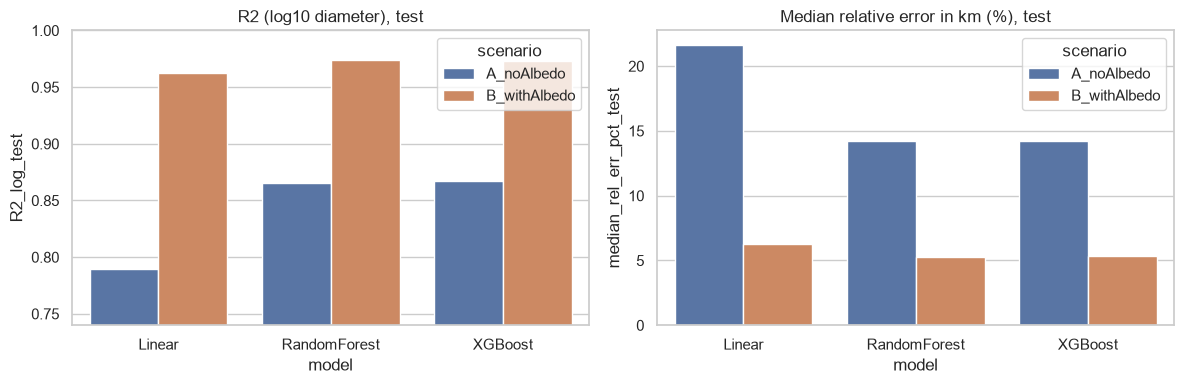

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=res, x="model", y="R2_log_test", hue="scenario", ax=axes[0]); axes[0].set_ylim(res["R2_log_test"].min() - 0.05, 1)
axes[0].set_title("R2 (log10 diameter), test")
sns.barplot(data=res, x="model", y="median_rel_err_pct_test", hue="scenario", ax=axes[1])
axes[1].set_title("Median relative error in km (%), test")
savefig("05_model_comparison")

### 5.1 Best model: predicted vs actual, residuals, where it fails

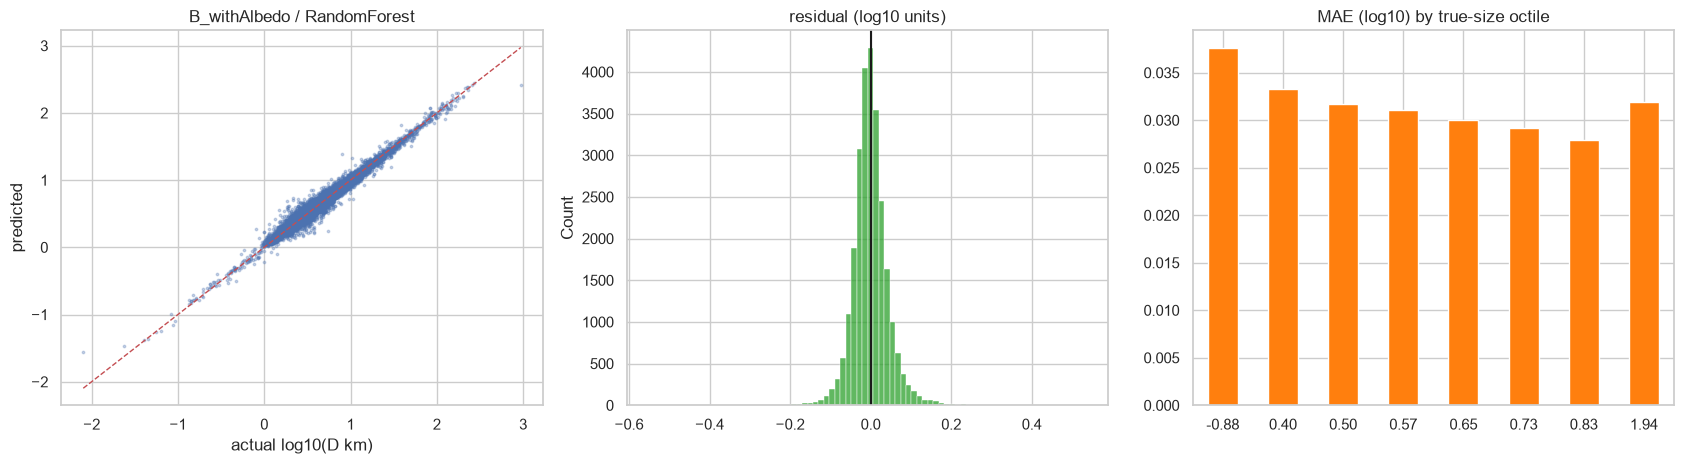

In [8]:
_, pipe, b_scen, b_model = best
feats = SCENARIOS[b_scen]
pt = preds[(b_scen, b_model)]
err = pt - test["log_diameter"].values

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].scatter(test["log_diameter"], pt, s=3, alpha=0.3)
lim = [test["log_diameter"].min(), test["log_diameter"].max()]; axes[0].plot(lim, lim, "r--", lw=1)
axes[0].set_xlabel("actual log10(D km)"); axes[0].set_ylabel("predicted"); axes[0].set_title(f"{b_scen} / {b_model}")
sns.histplot(err, bins=80, ax=axes[1], color="tab:green"); axes[1].axvline(0, color="k"); axes[1].set_title("residual (log10 units)")
bins = pd.qcut(test["log_diameter"], 8)
mae_by = pd.Series(np.abs(err)).groupby(bins.values).mean()
mae_by.plot.bar(ax=axes[2], color="tab:orange"); axes[2].set_title("MAE (log10) by true-size octile"); axes[2].set_xticklabels([f"{i.mid:.2f}" for i in mae_by.index], rotation=0)
savefig("05_best_model_diagnostics")

In [9]:
# error by orbital class (top 6) and the 10 worst misses
cls = test.assign(abs_err=np.abs(err)).groupby("class")["abs_err"].agg(["size", "mean"]).sort_values("size", ascending=False).head(6)
display(cls.round(4).rename(columns={"size": "n", "mean": "MAE_log10"}))
worst = test.assign(pred_km=10 ** pt, abs_err=np.abs(err)).nlargest(10, "abs_err")
worst[["full_name", "class", "H", "albedo", "diameter", "pred_km", "abs_err"]].round(3)

,n,MAE_log10
class,,
MBA,24092,0.0315
OMB,1457,0.0304
TJN,374,0.0262
IMB,96,0.0374
APO,85,0.0581
MCA,61,0.0540


,full_name,class,H,albedo,diameter,pred_km,abs_err
0,1 Ceres,MBA,3.400000,0.090,939.400024,264.373,0.551
25622,(2010 GH7),APO,27.299999,0.326,0.008000,0.027,0.536
25319,(2008 RN45),MBA,18.700001,0.031,5.500000,1.751,0.497
354,1806 Derice (1971 LC),MBA,12.000000,0.035,7.976000,24.622,0.490
24170,433744 (2015 AE256),MBA,15.700000,0.039,1.846000,4.866,0.421
23172,382148 (2011 MC3),MBA,15.400000,0.031,2.171000,5.438,0.399
25073,510065 (2010 HG59),MBA,16.299999,0.035,1.485000,3.606,0.385
25024,503086 (2015 FF290),MBA,15.500000,0.039,2.128000,5.017,0.372
25560,(2010 DT80),MCA,17.500000,0.058,0.795000,1.864,0.370
23621,404739 (2014 JG26),MBA,17.100000,0.138,3.745000,1.622,0.363


### 5.2 Stability: 5-fold CV of the best configuration on the train split

In [10]:
cv_rows = train_all if not TRAIN_CAP else train_all.sample(min(TRAIN_CAP, len(train_all)), random_state=U.SEED)
cv = cross_val_score(build(b_model), cv_rows[feats], cv_rows["log_diameter"], cv=KFold(5, shuffle=True, random_state=U.SEED), scoring="r2")
print(f"CV R2 (log10): {cv.mean():.4f} +- {cv.std():.4f}   folds={np.round(cv, 4)}")

CV R2 (log10): 0.9732 +- 0.0011   folds=[0.9721 0.9723 0.9735 0.9728 0.9751]


### 6. Save

In [11]:
bundle = {"pipeline": pipe, "features": feats, "scenario": b_scen, "model": b_model,
          "target": "log10(diameter in km)  ->  diameter = 10 ** prediction", "split_seed": U.SEED,
          "train_log_range": [float(train_all["log_diameter"].min()), float(train_all["log_diameter"].max())]}
out_path = U.MODELS / "case2_diameter_best.joblib"
joblib.dump(bundle, out_path, compress=3)
size_mb = out_path.stat().st_size / 1e6
print(f"saved {out_path}  ({size_mb:.1f} MB)  <- {b_scen} / {b_model}")
if size_mb > 90:
    print("WARNING: too big for a normal GitHub push (limit 100 MB). Lower RF_TREES / max_depth or raise min_samples_leaf and rerun.")

saved C:\Projects\Planetary_Defense_Analytics\models\case2_diameter_best.joblib  (17.8 MB)  <- B_withAlbedo / RandomForest
